# 02 — Dynamic Link Prediction with a Temporal Graph Neural Network

Trains and evaluates `TGNNLite` (a compact JODIE/TGN-style memory-based
temporal GNN, `src/pp_tgnn/model.py`) on the processed event stream from
notebook 01.

**Prerequisites:** run `01_preprocessing_pipeline.ipynb` first (or
`scripts/run_pipeline.py`) so that `../data/processed/` is populated.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pp_tgnn.model import TGNNLite
from pp_tgnn.train import build_node_vocab, encode_events, run_epoch, mrr_eval

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

PROC = Path("../data/processed")
events = pd.read_csv(PROC / "plant_pollinator_events.csv")
train = pd.read_csv(PROC / "events_train.csv")
val = pd.read_csv(PROC / "events_val.csv")
test = pd.read_csv(PROC / "events_test.csv")


device: cpu


## Build node vocabulary and encode splits

In [2]:
plant2idx, poll2idx, n_plants, n_polls = build_node_vocab(events)
train = encode_events(train, plant2idx, poll2idx)
val = encode_events(val, plant2idx, poll2idx)
test = encode_events(test, plant2idx, poll2idx)
n_nodes = n_plants + n_polls
print(f"n_plants={n_plants}  n_polls={n_polls}  n_nodes={n_nodes}")


n_plants=147  n_polls=800  n_nodes=947


## Model and training loop

In [3]:
model = TGNNLite(n_nodes, mem_dim=64, time_dim=16).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 5
history = []
for epoch in range(EPOCHS):
    model.reset_memory()
    loss, ap, auc = run_epoch(model, train, n_plants, n_polls, DEVICE, opt=opt, batch_size=200)
    history.append({"epoch": epoch, "loss": loss, "AP": ap, "AUC": auc})
    print(f"epoch {epoch}: train loss={loss:.4f}  AP={ap:.4f}  AUC={auc:.4f}")

history_df = pd.DataFrame(history)


epoch 0: train loss=0.5595  AP=0.7851  AUC=0.8322
epoch 1: train loss=0.4399  AP=0.8543  AUC=0.8725


epoch 2: train loss=0.4375  AP=0.8565  AUC=0.8763
epoch 3: train loss=0.4251  AP=0.8684  AUC=0.8830


epoch 4: train loss=0.4277  AP=0.8641  AUC=0.8808


## Chronological evaluation on val / test

In [4]:
model.reset_memory()
with torch.no_grad():
    run_epoch(model, train, n_plants, n_polls, DEVICE, opt=None, batch_size=200)  # warm up memory

val_loss, val_ap, val_auc = run_epoch(model, val, n_plants, n_polls, DEVICE, opt=None, batch_size=200)
print(f"val:  loss={val_loss:.4f}  AP={val_ap:.4f}  AUC={val_auc:.4f}")

test_loss, test_ap, test_auc = run_epoch(model, test, n_plants, n_polls, DEVICE, opt=None, batch_size=200)
print(f"test: loss={test_loss:.4f}  AP={test_ap:.4f}  AUC={test_auc:.4f}")


val:  loss=0.5191  AP=0.8489  AUC=0.8372
test: loss=0.4945  AP=0.8536  AUC=0.8643


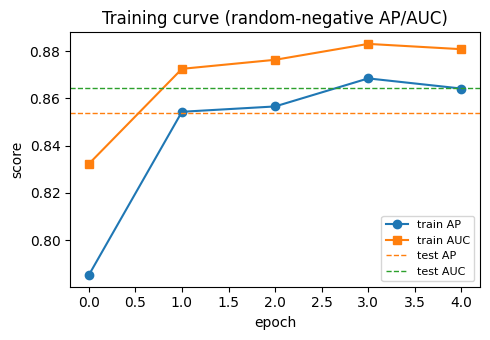

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(history_df["epoch"], history_df["AP"], marker="o", label="train AP")
ax.plot(history_df["epoch"], history_df["AUC"], marker="s", label="train AUC")
ax.axhline(test_ap, color="tab:orange", linestyle="--", linewidth=1, label="test AP")
ax.axhline(test_auc, color="tab:green", linestyle="--", linewidth=1, label="test AUC")
ax.set_xlabel("epoch"); ax.set_ylabel("score"); ax.legend(fontsize=8)
ax.set_title("Training curve (random-negative AP/AUC)")
fig.tight_layout(); plt.show()


## Ranking quality: Mean Reciprocal Rank

In [6]:
test_mrr = mrr_eval(model, test, n_plants, n_polls, DEVICE, n_neg=50, n_samples=300, seed=SEED)
chance_mrr = float(np.mean(1.0 / np.arange(1, 52)))
print(f"Test MRR (50 random negatives): {test_mrr:.4f}")
print(f"Chance-level MRR:               {chance_mrr:.4f}")


Test MRR (50 random negatives): 0.1914
Chance-level MRR:               0.0886


## Notes and extensions

- This is a compact ~150-line reference implementation (JODIE/TGN-lite:
  per-node GRU memory + functional time encoding + MLP decoder). It does not
  include full multi-head temporal attention over sampled neighborhoods or a
  raw-message store, as in the full TGN / TGAT architectures.
- The paper's key structural negatives (`plant_pollinator_negative_events.csv`)
  are watch-level absences without a specific pollinator identity, so they
  are not directly usable as negative *edges* — see `docs/data_dictionary.md`
  for the caveat and a documented approximation strategy.
- To move to a production-grade TGN: this notebook's `tau`, `u`/`v` (via
  `plant_id`/`pollinator_id`), and `c` columns map directly onto
  `torch_geometric.nn.models.TGNMemory`'s expected `t`, `src`/`dst`, and edge
  feature inputs, or the official TGN repo (github.com/twitter-research/tgn).


In [7]:
# Persist the trained model
torch.save(model.state_dict(), PROC / "tgnn_lite_state_dict.pt")
print("Saved:", (PROC / "tgnn_lite_state_dict.pt").resolve())


Saved: /home/claude/repo/pp-tgnn-dataset/data/processed/tgnn_lite_state_dict.pt
